# Lab 7: new CFD at the four high-Re Ghia cases

[Open in Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week04/W4_Lab7_High_Re_CFD_Ghia.ipynb)

**Question:** what changes when we actually solve the cavity at $Re=3200,5000,7500,10000$?
This lab reads newly computed full CFD fields on **128, 256 and 512 cells per side**.
It follows Lab 5 (benchmark/reference policy) and Lab 6 (the separate profile neural network).
The existing low-Re lessons and frozen neural fits are preserved.

Run All audits the saved results on a CPU. It does not submit HPC jobs or retrain a model.
The solver and production command are provided below for deliberate reproduction.

[Protocol and equations](../../docs/CAVITY_HIGH_RE_PROTOCOL.md) ·
[Native fields, figures and provenance](../../results/cavity_highre_ghia/README.md) ·
[Week 4 lecture](../../lectures/week04_cavity_surrogates_deeponet.pdf)

## 1. Physical and numerical problem

A unit square has a lid moving at $U=1$ and stationary no-slip other walls.
The discontinuity at the two upper corners is retained. Define $Re=UL/\nu$,
$u=\partial_y\psi$, $v=-\partial_x\psi$, and $\omega=\partial_xv-\partial_yu$.
The two steady equations are

$$\nabla^2\psi+\omega=0,\qquad
\frac{1}{Re}\nabla^2\omega-u\partial_x\omega-v\partial_y\omega=0.$$

Central differences and Thom wall vorticity match the existing Week-4 spatial
formulation. Damped Newton solves the steady equations with an analytical
Jacobian; continuation in Re supplies an initial state. **No Ghia values enter
these PDE solves.** Newton iteration count is not physical time.

A small equation residual establishes a discrete root. It does not establish
mesh independence, long-time stability or a three-dimensional physical flow.
We do not reconstruct pressure in this extension.

In [1]:
from pathlib import Path
import sys, subprocess
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents, Path('/content/FlowMLLab')]
             if (p/'flowmllab/ghia.py').is_file()), None)
if ROOT is None:
    candidate = Path('/content/FlowMLLab') if Path('/content').is_dir() else Path.cwd()/'FlowMLLab'
    if not candidate.exists():
        subprocess.run(['git','clone','--depth','1','https://github.com/Ehsan-Roohi/FlowMLLab.git',str(candidate)],check=True)
    if not (candidate/'flowmllab/ghia.py').is_file():
        raise RuntimeError('This checkout predates the cavity extension. Use an updated FlowMLLab checkout after saving your student work; do not overwrite your edited notebook.')
    ROOT = candidate
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from flowmllab import ghia, cavity_course as course

from flowmllab import cavity_highre as high
if not (ROOT/'results/cavity_highre_ghia/n512/re10000.npz').is_file():
    raise RuntimeError('Use a complete FlowMLLab v1.13.0 or newer checkout; the original low-Re bundle is insufficient.')
cases = high.load_cases(ROOT)  # SHA256, PDE, boundaries and continuity
scores = pd.DataFrame(high.score_rows(cases))
print(f'Independently checked {len(cases)} actual CFD fields.')
display(scores[['Re','cells','steady_vorticity_linf','poisson_linf','continuity_linf']])

Independently checked 12 actual CFD fields.


,Re,cells,steady_vorticity_linf,poisson_linf,continuity_linf
0,3200,128,2.047784e-10,1.881384e-12,7.105427e-15
1,3200,256,5.615561e-10,8.020029e-12,1.421085e-14
2,3200,512,4.920011e-10,3.244716e-11,2.842171e-14
3,5000,128,2.202327e-10,1.775247e-12,7.105427e-15
4,5000,256,1.077410e-09,7.685186e-12,1.421085e-14
5,5000,512,9.625865e-10,3.140133e-11,2.842171e-14
6,7500,128,5.559784e-10,1.810108e-12,7.105427e-15
7,7500,256,3.613231e-09,7.704504e-12,1.421085e-14
8,7500,512,7.270160e-09,3.140821e-11,2.842171e-14
9,10000,128,5.133813e-10,1.809441e-12,3.552714e-15


## 2. Look at the physical flow first

The black curves below are streamlines of the newly calculated finest-grid
velocity. Compare the primary vortex and the corner recirculations as Re grows.
A weak small vortex may be poorly represented by automatic streamline seeding:
inspect streamfunction contours in the exercise, rather than inferring absence
from an empty-looking corner.

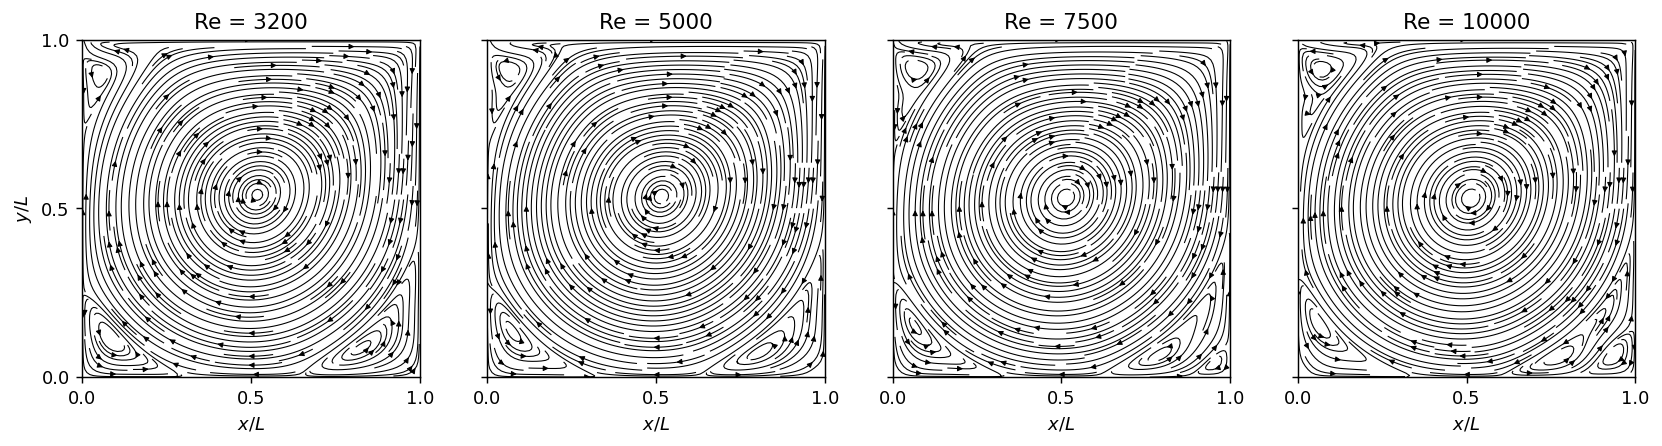

In [2]:
fig = high.plot_streamlines(cases)
plt.show()

## 3. All four new comparisons with Ghia

Each panel contains our three independently converged CFD grids and the original
published samples. The cross retains a previously flagged printed entry: the
$u/U=-0.86636$ point at $Re=3200, y/L=0.4531$, or $+0.03111$ at
$Re=10000, y/L=0.5$. These are a sensitivity policy, not a claimed erratum.
We show both all-point and screened metrics below. Nothing is silently deleted.

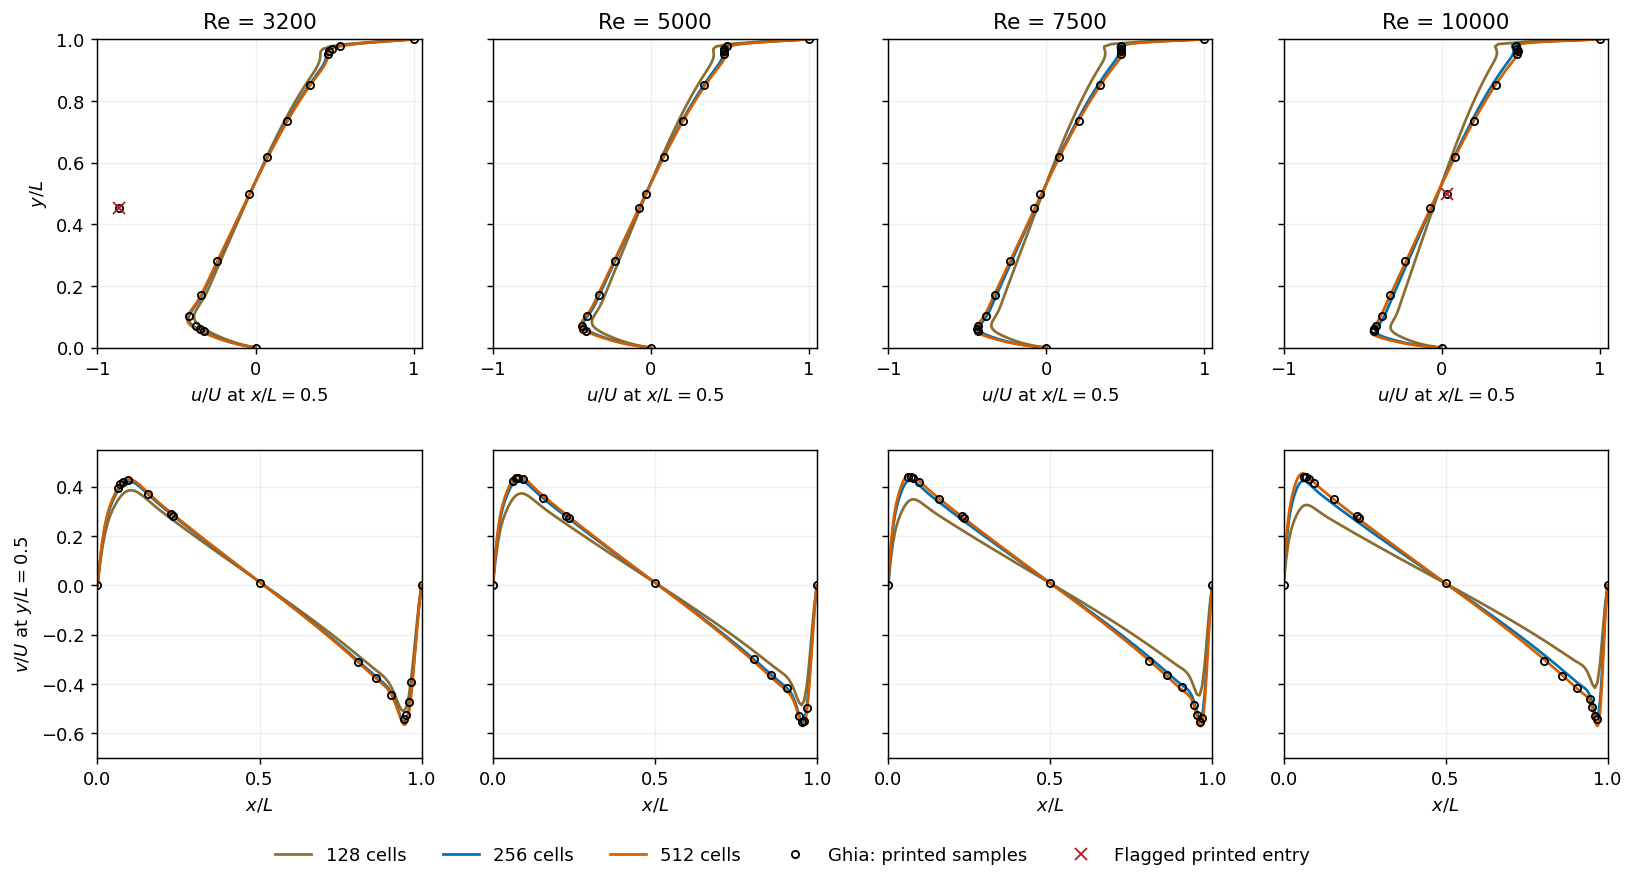

,Re,u_published_relative_l2,u_screened_relative_l2,v_published_relative_l2,v_screened_relative_l2,u_screened_rmse_U,v_screened_rmse_U
2,3200,0.415516,0.030394,0.047732,0.047732,0.012802,0.017788
5,5000,0.016099,0.016099,0.021369,0.021369,0.006653,0.008279
8,7500,0.018221,0.018221,0.022401,0.022401,0.007566,0.008635
11,10000,0.039547,0.020584,0.025240,0.025240,0.008806,0.009576


In [3]:
fig = high.plot_overview(cases)
plt.show()
finest_scores = scores[scores.cells==512].copy()
display(finest_scores[['Re','u_published_relative_l2','u_screened_relative_l2',
                      'v_published_relative_l2','v_screened_relative_l2',
                      'u_screened_rmse_U','v_screened_rmse_U']])

For a chosen Re, inspect the flow and both centreline profiles at a larger size.
Change `RE_TO_INSPECT` to any one of the four values; do not alter the reference data.

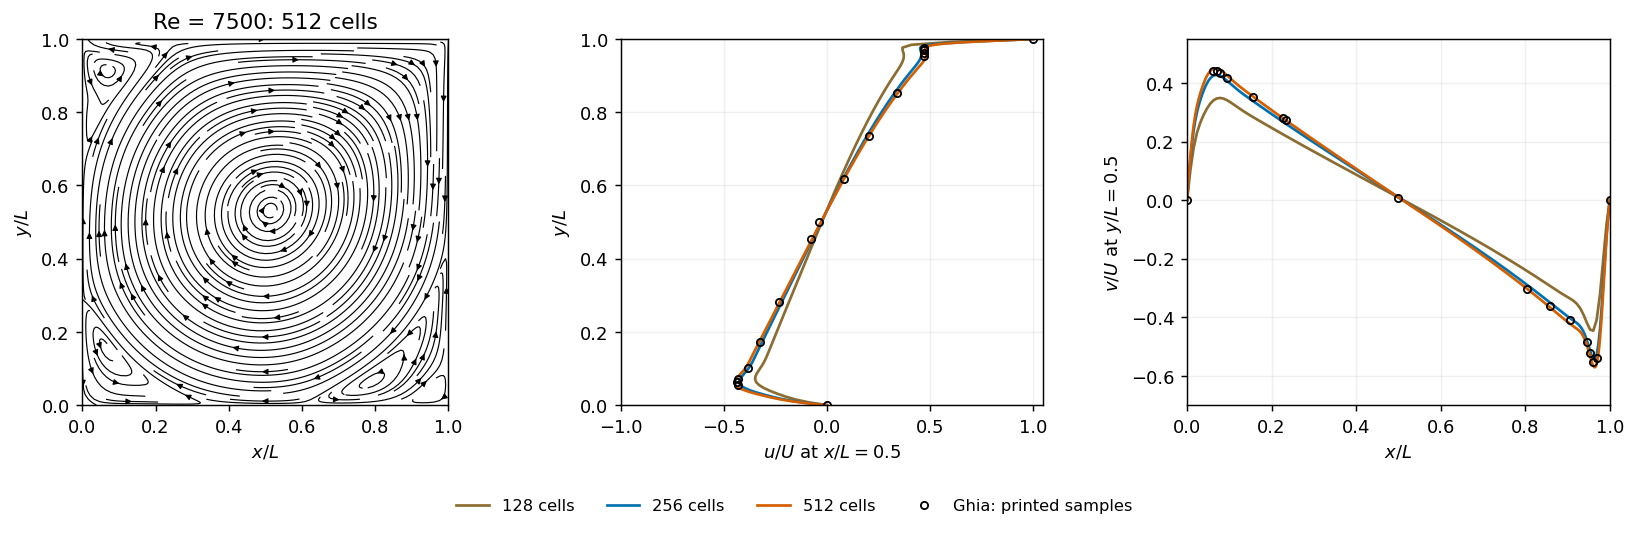

In [4]:
RE_TO_INSPECT = 7500
fig = high.plot_case(cases, RE_TO_INSPECT)
plt.show()

## 4. How much does the mesh still change the answer?

The following table compares the 128- and 256-cell profiles with the 512-cell
profile at the same 2049 evaluation locations. This dense interpolation is only
for comparing CFD curves; it does not manufacture more Ghia observations.
RMSE and maximum differences are normalized by lid speed, with signs retained
in the profile plots. Do not equate the smallest Ghia error with the best mesh:
the benchmark table has its own numerical error and sparse coverage.

In [5]:
mesh = pd.DataFrame(high.mesh_rows(cases))
display(mesh)
# Native values at fixed positions, evaluated in the same way on each mesh.
positions = np.array([0.05, 0.10, 0.50, 0.90, 0.95])
samples = []
for case in cases:
    for component in ('u','v'):
        values = np.interp(positions, *case['profiles'][component])
        samples.extend(dict(Re=case['Re'], cells=case['cells'], component=component,
                            position=float(t), velocity_U=float(q))
                       for t,q in zip(positions,values))
sample_table = pd.DataFrame(samples)
display(sample_table[sample_table.Re==RE_TO_INSPECT])

,Re,cells,reference_cells,velocity_relative_l2,velocity_vector_rms_U,velocity_component_linf_U,u_rmse_U,u_linf_U,v_rmse_U,v_linf_U
0,3200,128,512,0.093311,0.028870,0.291035,0.026156,0.053769,0.026999,0.069897
1,3200,256,512,0.020252,0.006215,0.165595,0.005477,0.011273,0.005631,0.015020
2,5000,128,512,0.144281,0.044688,0.362017,0.040475,0.083131,0.041632,0.110038
3,5000,256,512,0.031444,0.009656,0.201149,0.008652,0.017735,0.008845,0.023754
4,7500,128,512,0.209790,0.064807,0.432043,0.058442,0.119384,0.059995,0.162119
5,7500,256,512,0.047195,0.014447,0.248111,0.013025,0.026665,0.013268,0.036192
6,10000,128,512,0.265019,0.081513,0.521088,0.073232,0.148875,0.075121,0.201880
7,10000,256,512,0.063226,0.019260,0.290762,0.017355,0.035421,0.017650,0.048214


,Re,cells,component,position,velocity_U
60,7500,128,u,0.05,-0.314325
61,7500,128,u,0.10,-0.323586
62,7500,128,u,0.50,-0.024167
63,7500,128,u,0.90,0.325945
64,7500,128,u,0.95,0.372904
65,7500,128,v,0.05,0.319153
66,7500,128,v,0.10,0.336495
67,7500,128,v,0.50,0.009285
68,7500,128,v,0.90,-0.331002
69,7500,128,v,0.95,-0.432207


## 5. Physical time is a separate test

On 256 cells, both time steps ($0.002$ and $0.001$) start from the same steady
field plus $\delta\psi=10^{-4}\sin^2(\pi x)\sin^2(\pi y)$.
Vorticity is changed consistently by $\delta\omega=-\nabla_h^2\delta\psi$.
SSPRK3 uses a fresh Poisson and wall-vorticity solve at every stage.
The observation times match exactly from $tU/L=0$ to $10$.

The paired trajectory difference tests time discretization. Growth or decay over
this short interval **does not settle asymptotic stability**, and this single
perturbation does not probe every possible mode. In particular, a steady Newton
root at Re=10000 is not evidence of stable physical flow.

,Re,cells,time_end,dt_coarse,dt_fine,paired_velocity_rms_difference_U,paired_velocity_linf_difference_U,relative_perturbation_difference,initial_departure_rms_U,final_departure_rms_U,finite_horizon_growth,finite_horizon_time_check_pass
0,3200,256,10,0.002,0.001,1.070748e-12,2.948752e-12,6.873451e-09,0.000192,0.000156,0.812987,True
1,5000,256,10,0.002,0.001,2.234917e-12,6.661283e-12,1.325910e-08,0.000192,0.000169,0.879667,True
2,7500,256,10,0.002,0.001,8.731586e-12,4.324574e-11,4.847611e-08,0.000192,0.000180,0.940019,True
3,10000,256,10,0.002,0.001,2.570625e-11,1.632892e-10,1.234108e-07,0.000192,0.000208,1.087068,True


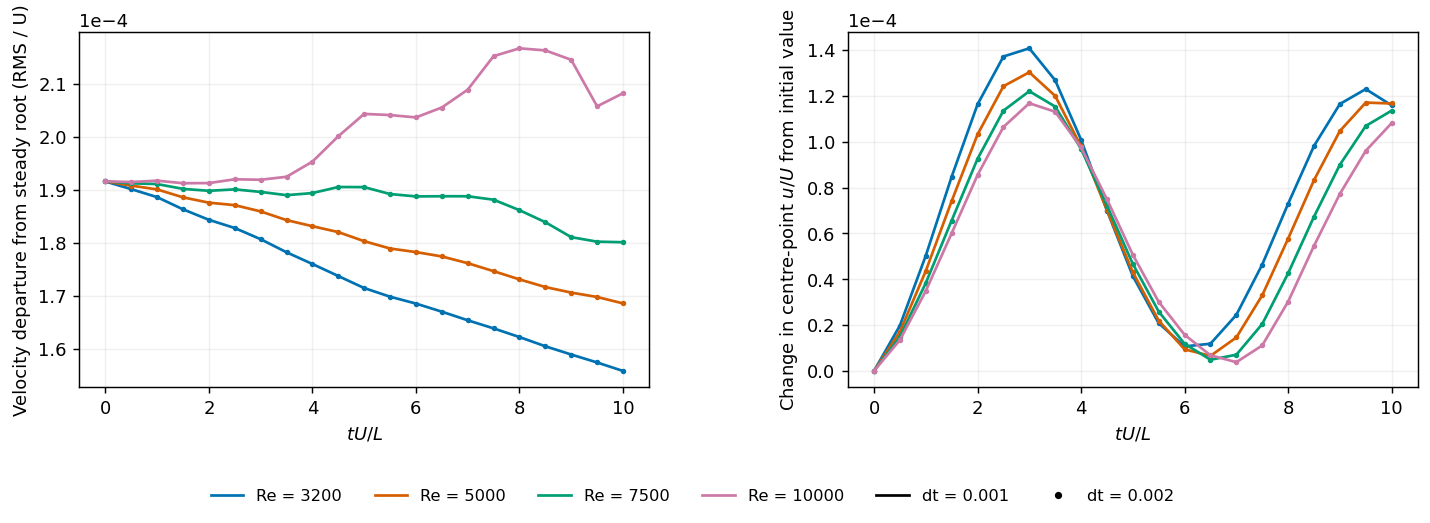

In [6]:
time_rows, time_pairs = high.load_temporal(ROOT)
time_table = pd.DataFrame(time_rows)
display(time_table)
fig = high.plot_temporal(time_pairs)
plt.show()

## 6. Reproduce a solver run deliberately

The CPU production entry point is `qa/run_cavity_highre.py`; it stores one
configuration-matched complete continuation checkpoint and the four target
fields. It requires NumPy and SciPy. The 512-cell sparse factorizations are more
expensive than the default notebook audit; do not launch them by accident.

```bash
python qa/run_cavity_highre.py --cells 256 \
  --seed results/week01_2_formulations/streamfunction-vorticity-re1000-n128.npz \
  --output /your/allocated/scratch/cavity-highre
```

For Unity, allocate/discover the actual Workspace first. The retained batch
script records this campaign's real scratch path; replace that path with your
own allocated path when reproducing. The saved metadata includes source hashes,
seed identity, all continuation trials, convergence and runtime. The initial
failed direct 1000-to-3200 Newton jump is documented in the protocol.

## 7. Engineering exercises and required deliverables

**Exercise A — compute, do not just inspect.** For every Re, report the finest-grid
u and v RMSE/U, all-point relative L2 error, screened relative L2 error, and the
number of excluded reference points. Use `scores` from Section 3. Explain
numerically why the two Re=3200 u metrics differ. Do not hide the printed sample.

**Exercise B — mesh decision.** From the Section 4 `mesh` table, compare 128-to-512
and 256-to-512 RMSE and maximum errors. For each component/Re, state whether a
1% of U maximum-profile-change requirement is met by the 256-cell mesh. Use the
actual numbers; a failed requirement is a valid result. On two separate axes,
plot the signed 256-minus-512 u and v differences against centreline position.
Explain why this is a sensitivity check rather than a formal Richardson estimate.

**Exercise C — secondary vortices.** For Re=3200 and 10000 on all three grids,
plot signed streamfunction contours in the bottom-right square
$0.65\le x/L\le1$, $0\le y/L\le0.35$. Report the maximum positive streamfunction
and its coordinates in that region. Show whether refinement shifts or changes
the secondary vortex. Supply one physical contour plot, not a bar chart.

**Exercise D — time and convergence.** From the Section 5 `time_table`, report the
paired RMS difference and final/initial perturbation RMS for all four Re.
Identify the largest short-time growth and the largest time-step discrepancy.
Explain why tiny Newton residuals and a small dt discrepancy do not prove
long-time stability. Design a further test with a longer window, a finer spatial
grid and more than one perturbation; distinguish your design from a completed run.

**Exercise E — honest machine learning.** Read the frozen split and scores in
Lab 6. Explain the difference between its centreline-data MLP and a full-field
supervised operator trained on these new CFD fields; a data-free PINN uses PDE
residuals instead of CFD labels. Lab 8 supplies the actual full-field experiment. List what information the latter
would see, which whole Re cases would be withheld, and what independent fields
and equation checks you would use. Re=3200 and 7500 tests from Lab 6 are already
disclosed; tuning against them requires a fresh test for a new research claim.
Compare the Lab 8 validation and test tables with your design. Keep its
supervised neural results distinct from the CFD evidence in this notebook.

Submit: one numerical table for A/B/D, the signed profile plot for B, the physical
corner-vortex comparison for C, and a concise interpretation for D/E. Include
source version and native field hashes so the results are traceable.